# K-Nearest Neighbours
**Name:** GUNTI RAHUL |  **Roll No:** CH.SC.U4CSE24211
**Course:** Machine Learning (23CSE301)  |  **Lab Activity Book:** Chapter 9.6

## Exercise 1 - Handwritten digit recognition
The book points to a text-image digits set; here sklearn's bundled `digits` (1,797 images, 8x8 pixels) is used. A kNN classifier labels a new image by the digits it most resembles.

images: (1797, 8, 8) | classes: [0 1 2 3 4 5 6 7 8 9]


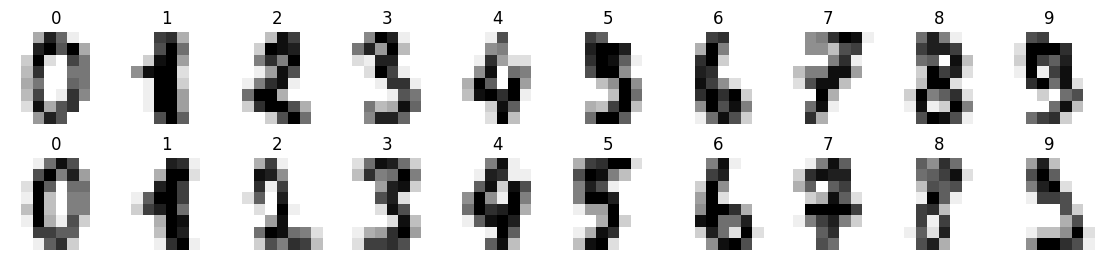

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_digits
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

digits = load_digits()
print("images:", digits.images.shape, "| classes:", np.unique(digits.target))
fig, ax = plt.subplots(2, 10, figsize=(14, 3))
for i, a in enumerate(ax.ravel()): a.imshow(digits.images[i], cmap="gray_r"); a.set_title(digits.target[i]); a.axis("off")
plt.show()

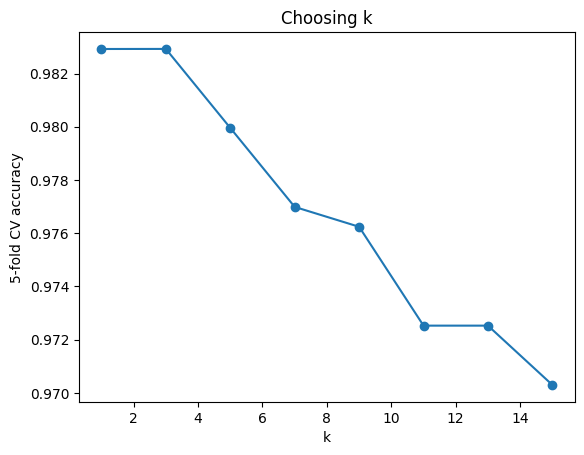

Best k: 3


In [2]:
Xtr, Xte, ytr, yte = train_test_split(digits.data, digits.target, test_size=.25, random_state=262, stratify=digits.target)
ks = range(1, 16, 2)
cv = [cross_val_score(KNeighborsClassifier(k), Xtr, ytr, cv=5).mean() for k in ks]
plt.plot(list(ks), cv, "o-"); plt.xlabel("k"); plt.ylabel("5-fold CV accuracy"); plt.title("Choosing k"); plt.show()
bestk = list(ks)[int(np.argmax(cv))]; print("Best k:", bestk)

Test accuracy: 0.9956
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        45
           1       1.00      1.00      1.00        46
           2       1.00      1.00      1.00        44
           3       1.00      1.00      1.00        46
           4       1.00      1.00      1.00        45
           5       0.98      1.00      0.99        46
           6       1.00      1.00      1.00        45
           7       1.00      0.98      0.99        45
           8       1.00      1.00      1.00        43
           9       0.98      0.98      0.98        45

    accuracy                           1.00       450
   macro avg       1.00      1.00      1.00       450
weighted avg       1.00      1.00      1.00       450



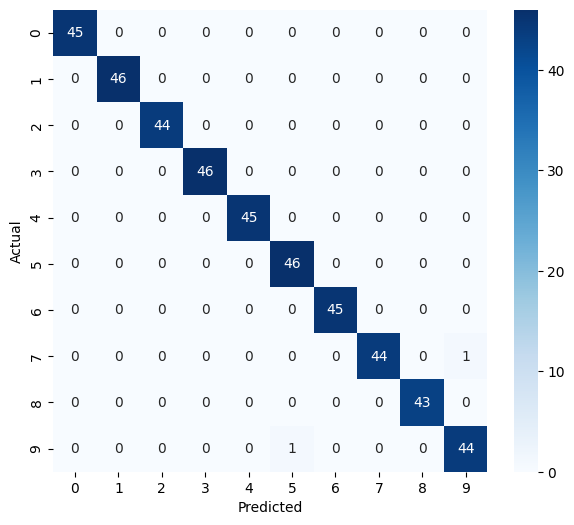

In [3]:
knn = KNeighborsClassifier(bestk, weights="distance").fit(Xtr, ytr); pred = knn.predict(Xte)
print("Test accuracy:", round(accuracy_score(yte, pred), 4)); print(classification_report(yte, pred))
plt.figure(figsize=(7, 6)); sns.heatmap(confusion_matrix(yte, pred), annot=True, fmt="d", cmap="Blues"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

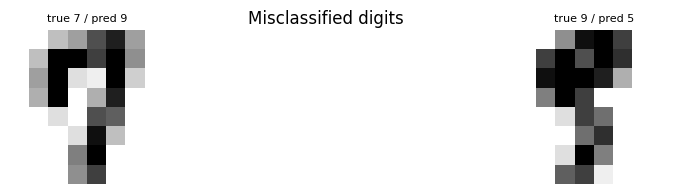

Neighbours of test image 0 have labels: [1 1 1 1 1] -> prediction 1 (actual 1 )


In [4]:
wrong = np.where(pred != yte)[0][:8]
fig, ax = plt.subplots(1, max(len(wrong), 1), figsize=(12, 2))
for a, i in zip(np.atleast_1d(ax), wrong):
    a.imshow(Xte[i].reshape(8, 8), cmap="gray_r"); a.set_title(f"true {yte[i]} / pred {pred[i]}", fontsize=8); a.axis("off")
plt.suptitle("Misclassified digits"); plt.show()
dist, idx = knn.kneighbors(Xte[:1], n_neighbors=5)
print("Neighbours of test image 0 have labels:", ytr[idx[0]], "-> prediction", pred[0], "(actual", yte[0], ")")

## Exercise 2 - Euclidean distance to a new entry
The book doesn't supply the new point, so I take **Brightness = 20, Saturation = 35**. The distance to each stored row is

`d = sqrt((B1 - B2)^2 + (S1 - S2)^2)`

In [5]:
colors = pd.DataFrame({"Brightness": [40, 50, 60, 10, 70, 60, 25], "Saturation": [20, 50, 90, 25, 70, 10, 80],
                       "Class": ["Red", "Blue", "Blue", "Red", "Blue", "Red", "Blue"]})
new = (20, 35)

def euclid(row, point):
    return np.sqrt((row.Brightness - point[0]) ** 2 + (row.Saturation - point[1]) ** 2)

colors["Distance"] = colors.apply(euclid, axis=1, point=new)
ranked = colors.sort_values("Distance").reset_index(drop=True); ranked.index += 1; ranked.round(3)

,Brightness,Saturation,Class,Distance
1,10,25,Red,14.142
2,40,20,Red,25.000
3,50,50,Blue,33.541
4,25,80,Blue,45.277
5,60,10,Red,47.170
6,70,70,Blue,61.033
7,60,90,Blue,68.007


k=1: votes {'Red': 1} -> Red
k=3: votes {'Red': 2, 'Blue': 1} -> Red
k=5: votes {'Red': 3, 'Blue': 2} -> Red


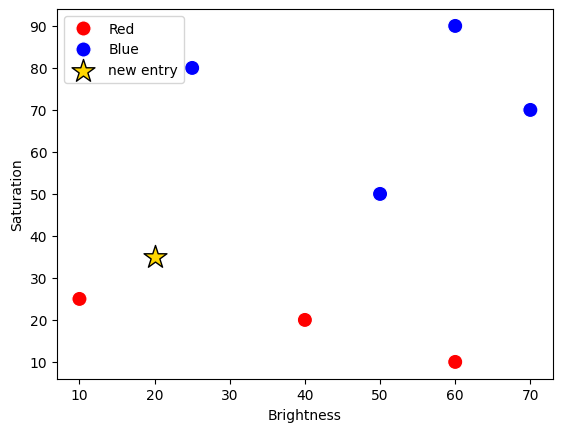

In [6]:
for k in (1, 3, 5):
    vote = ranked.head(k).Class.value_counts()
    print(f"k={k}: votes {vote.to_dict()} -> {vote.idxmax()}")
sc = sns.scatterplot(data=colors, x="Brightness", y="Saturation", hue="Class", palette={"Red": "red", "Blue": "blue"}, s=120)
plt.scatter(*new, marker="*", s=300, c="gold", edgecolor="k", label="new entry"); plt.legend(); plt.show()

### Conclusion
k is chosen by cross-validation rather than guessed, distance weighting helps close calls, and the errors cluster on visually similar digits (e.g. 8/9, 3/5). For the colour table, the nearest rows are Red, so the new entry is classed **Red** for k = 1, 3 and 5.